In [1]:
import warnings
warnings.filterwarnings("ignore")

# Clustering and K-Means

Objectives:
* Describe clustering use cases in machine learning applications.
* Choose the appropriate similarity measure for an analysis.
* Cluster data with the k-means algorithm.
* Evaluate the quality of clustering results.

## What is clustering?

Suppose you are working with a dataset that includes patient information from a healthcare system. The dataset is complex and includes both categorical and numeric features. You want to find patterns and similarities in the dataset. How might you approach this task?

Clustering is an unsupervised machine learning technique designed to group unlabeled examples based on their similarity to each other. (If the examples are labeled, this kind of grouping is called classification.) Consider a hypothetical patient study designed to evaluate a new treatment protocol. During the study, patients report how many times per week they experience symptoms and the severity of the symptoms. Researchers can use clustering analysis to group patients with similar treatment responses into clusters. Figure 1 demonstrates one possible grouping of simulated data into three clusters.

<figure>
<img src="./figures/clustering_example.png" alt="Figure 1: Unlabeled examples grouped into three clusters (simulated data)." style="width: 700px;"/>
<figcaption><b><i>Figure 1: Unlabeled examples grouped into three clusters (simulated data).</i></b></figcaption>
</figure>

Looking at the unlabeled data on the left of Figure 1, you could guess that the data forms three clusters, even without a formal definition of similarity between data points. In real-world applications, however, you need to explicitly define a <b>similarity measure</b>, or the metric used to compare samples, in terms of the dataset's features. When examples have only a couple of features, visualizing and measuring similarity is straightforward. But as the number of features increases, combining and comparing features becomes less intuitive and more complex. Different similarity measures may be more or less appropriate for different clustering scenarios, and this course will address choosing an appropriate similarity measure.

After clustering, each group is assigned a unique label called a <b>cluster ID</b>. Clustering is powerful because it can simplify large, complex datasets with many features to a single cluster ID.

## Clustering use cases

Clustering is useful in a variety of industries. Some common applications for clustering:

* Market segmentation
* Social network analysis
* Search result grouping
* Medical imaging
* Image segmentation
* Anomaly detection

Some specific examples of clustering:

* The <a href="https://en.wikipedia.org/wiki/Hertzsprung%e2%80%93Russell_diagram">Hertzsprung-Russell diagram</a> shows clusters of stars when plotted by luminosity and temperature.
* Gene sequencing that shows previously unknown genetic similarities and dissimilarities between species has led to the revision of taxonomies previously based on appearances.
* The <a href="https://en.wikipedia.org/wiki/Big_Five_personality_traits">Big 5</a> model of personality traits was developed by clustering words that describe personality into 5 groups. The <a href="https://en.wikipedia.org/wiki/HEXACO_model_of_personality_structure">HEXACO</a> model uses 6 clusters instead of 5.

### Imputation

When some examples in a cluster have missing feature data, you can infer the missing data from other examples in the cluster. This is called imputation. For example, less popular videos can be clustered with more popular videos to improve video recommendations.

### Data compression

As discussed, the relevant cluster ID can replace other features for all examples in that cluster. This substitution reduces the number of features and therefore also reduces the resources needed to store, process, and train models on that data. For very large datasets, these savings become significant.

To give an example, a single YouTube video can have feature data including:

* viewer location, time, and demographics
* comment timestamps, text, and user IDs
* video tags

Clustering YouTube videos replaces this set of features with a single cluster ID, thus compressing the data.

### Privacy preservation

You can preserve privacy somewhat by clustering users and associating user data with cluster IDs instead of user IDs. To give one possible example, say you want to train a model on YouTube users' watch history. Instead of passing user IDs to the model, you could cluster users and pass only the cluster ID. This keeps individual watch histories from being attached to individual users. Note that the cluster must contain a sufficiently large number of users in order to preserve privacy.

# Clustering algorithms

Machine learning datasets can have millions of examples, but not all clustering algorithms scale efficiently. Many clustering algorithms compute the similarity between all pairs of examples, which means their runtime increases as the square of the number of examples $n$, denoted as $O(n^2)$  in complexity notation. $O(n^2)$ algorithms are not practical for datasets with millions of examples.

The k-means algorithm has a complexity of $O(n)$, meaning that the algorithm scales linearly with $n$. This algorithm will be the focus of this course.

### Types of clustering

For an exhaustive list of different approaches to clustering, see <a href="https://link.springer.com/article/10.1007/s40745-015-0040-1">  A Comprehensive Survey of Clustering Algorithms</a> Xu, D. & Tian, Y. Ann. Data. Sci. (2015) 2: 165. Each approach is best suited to a particular data distribution. This course briefly discusses four common approaches.

## Centroid-based clustering

The <b>centroid</b> of a cluster is the arithmetic mean of all the points in the cluster. <b>Centroid-based clustering</b> organizes the data into non-hierarchical clusters. Centroid-based clustering algorithms are efficient but sensitive to initial conditions and outliers. Of these, k-means is the most widely used. It requires users to define the number of centroids, k, and works well with clusters of roughly equal size.

<figure>
<img src="./figures/CentroidBasedClustering.svg" style="width: 500px;"/>
<figcaption><b><i> Figure 2: Example of centroid-based clustering.</i></b></figcaption>
</figure>

## Density-based clustering

Density-based clustering connects contiguous areas of high example density into clusters. This allows for the discovery of any number of clusters of any shape. Outliers are not assigned to clusters. These algorithms have difficulty with clusters of different density and data with high dimensions.

<figure>
<img src="./figures/DensityClustering.svg" style="width: 500px;"/>
<figcaption><b><i> Figure 3: Example of density-based clustering.</i></b></figcaption>
</figure>

## Distribution-based clustering

This clustering approach assumes data is composed of probabilistic distributions, such as <a href="https://wikipedia.org/wiki/Normal_distribution">Gaussian distributions.</a> In Figure 4, the distribution-based algorithm clusters data into three Gaussian distributions. As distance from the distribution's center increases, the probability that a point belongs to the distribution decreases. The bands show that decrease in probability. When you're not comfortable assuming a particular underlying distribution of the data, you should use a different algorithm.

<figure>
<img src="./figures/DistributionClustering.svg" style="width: 500px;"/>
<figcaption><b><i> Figure 4: Example of distribution-based clustering.</i></b></figcaption>
</figure>

## Hierarchical clustering

<b>Hierarchical clustering</b> creates a tree of clusters. Hierarchical clustering, not surprisingly, is well suited to hierarchical data, such as taxonomies. See <a href="https://www.researchgate.net/figure/Pan-genome-clustering-of-E-coli-black-and-related-species-colored-based-on-the_fig1_45152238">Comparison of 61 Sequenced Escherichia coli Genomes</a> by Oksana Lukjancenko, Trudy Wassenaar & Dave Ussery for an example. Any number of clusters can be chosen by cutting the tree at the right level.

<figure>
<img src="./figures/HierarchicalClustering.svg" style="width: 600px;"/>
<figcaption><b><i> Figure 5: Example of a hierarchical tree clustering animals.</i></b></figcaption>
</figure>



# Clustering workflow

To cluster your data, you'll follow these steps:

1. Prepare data.
2. Create similarity metric.
3. Run clustering algorithm.
4. Interpret results and adjust your clustering.

Here we briefly introduce the steps. We'll go into depth in subsequent sections.

#### Prepare data
As with any ML problem, you must normalize, scale, and transform feature data before training or fine-tuning a model on that data. In addition, before clustering, check that the prepared data lets you accurately calculate similarity between examples.

#### Create similarity metric
Before a clustering algorithm can group data, it needs to know how similar pairs of examples are. You can quantify the similarity between examples by creating a similarity metric, which requires a careful understanding of your data.

#### Run clustering algorithm
A clustering algorithm uses the similarity metric to cluster data. This course uses k-means.

#### Interpret results and adjust
Because clustering doesn't produce or include a ground "truth" against which you can verify the output, it's important to check the result against your expectations at both the cluster level and the example level. If the result looks odd or low-quality, experiment with the previous three steps. Continue iterating until the quality of the output meets your needs.

# K-means clustering

## What is k-means clustering?

As previously mentioned, many clustering algorithms don't scale to the datasets used in machine learning, which often have millions of examples. For example, agglomerative or divisive hierarchical clustering algorithms look at all pairs of points and have complexities of $O(n^2log(n))$ and $O(n^2)$, respectively.

This course focuses on k-means because it scales as $O(nk)$, where $k$ is the number of clusters chosen by the user. This algorithm groups points into $k$ clusters by minimizing the distances between each point and its cluster's centroid (see Figure 6).

As a result, k-means effectively treats data as composed of a number of roughly circular distributions, and tries to find clusters corresponding to these distributions. But real-world data contains outliers and density-based clusters and might not match the assumptions underlying k-means.

### k-means clustering algorithm
The algorithm follows these steps:

1. Provide an initial guess for $k$, which can be revised later. For this example, we choose $k=3$.
2. Randomly choose $k$ centroids.

<figure>
<img src="./figures/Initialization.svg" style="width: 300px;"/>
<figcaption><b><i> Figure 6: k-means at initialization.</i></b></figcaption>
</figure>

3. Assign each point to the nearest centroid to get $k$ initial clusters.

<figure>
<img src="./figures/Step2.svg" style="width: 300px;"/>
<figcaption><b><i> Figure 7: Initial clusters.</i></b></figcaption>
</figure>

4. For each cluster, calculate a new centroid by taking the mean position of all points in the cluster. The arrows in Figure 8 show the change in centroid positions.

<figure>
<img src="./figures/Step3.svg" style="width: 300px;"/>
<figcaption><b><i> Figure 8: Recomputed centroids.</i></b></figcaption>
</figure>

5. Reassign each point to the nearest new centroid.

<figure>
<img src="./figures/Step4.svg" style="width: 300px;"/>
<figcaption><b><i> Figure 9: Clusters after reassignment.</i></b></figcaption>
</figure>

6. Repeat steps 4 and 5, recalculating centroids and cluster membership, until points no longer change clusters. In the case of large datasets, you can stop the algorithm before convergence based on other criteria.

Because the centroid positions are initially chosen at random, k-means can return significantly different results on successive runs. To solve this problem, run k-means multiple times and choose the result with the best quality metrics. (We'll describe quality metrics later in this course.) You'll need an advanced version of k-means to choose better initial centroid positions.

Though a deep understanding of the math is not necessary, for those who are curious, k-means is a special case of the <a href="https://wikipedia.org/wiki/Expectation%E2%80%93maximization_algorithm">expectation-maximization algorithm.</a> See <a href="https://alliance.seas.upenn.edu/%7Ecis520/dynamic/2021/wiki/index.php?n=Lectures.EM#toc-1.2">lecture notes on the topic</a> from UPenn.

# Manual similarity measure 

As just shown, k-means assigns points to their closest centroid. But what does "closest" mean?

To apply k-means to feature data, you will need to define a measure of similarity that combines all the feature data into a single numeric value, called a <b>manual similarity measure.</b>

Consider a shoe dataset. If that dataset has shoe size as its only feature, you can define the similarity of two shoes in terms of the difference between their sizes. The smaller the numerical difference between sizes, the greater the similarity between shoes.

If that shoe dataset had two numeric features, size and price, you can combine them into a single number representing similarity. First scale the data so both features are comparable:

Size (s): Shoe size probably forms a Gaussian distribution. Confirm this. Then normalize the data.
Price (p): The data is probably a Poisson distribution. Confirm this. If you have enough data, convert the data to quantiles and scale to $[0,1]$

Next, combine the two features by calculating the root mean squared error (RMSE). This rough measure of similarity is given by $\sqrt{\frac{(s_i - s_j)^2 + (p_i - p_j)^2}{2}}$

For a simple example, calculate similarity for two shoes with US sizes 8 and 11, and prices 120 and 150. Since we don't have enough data to understand the distribution, we'll scale the data without normalizing or using quantiles.

<figure>
<img src="./figures/similarity_table.png" style="width: 600px;"/>
</figure>

Intuitively, your similarity measure should increase when feature data is more similar. Instead, your similarity measure (RMSE) actually decreases. Make your similarity measure follow your intuition by subtracting it from 1.

$Similarity = 1 - 0.17 = 0.83$

In general, you can prepare numerical data as described in Prepare data, then combine the data by using <a href="https://en.wikipedia.org/wiki/Euclidean_distance">Euclidean distance.</a>

What if that dataset included both shoe size and shoe color? Categorical data is harder to combine with the numerical size data. It can be:
* Single-valued (univalent), such as a car's color ("white" or "blue" but never both)
* Multi-valued (multivalent), such as a movie's genre (a movie can be both "action" and "comedy," or only "action")
If univalent data matches, for example in the case of two pairs of blue shoes, the similarity between the examples is 1. Otherwise, similarity is 0.

Multivalent data, like movie genres, is harder to work with. If there are a fixed set of movie genres, similarity can be calculated using the ratio of common values, called <a href="https://wikipedia.org/wiki/Jaccard_index">Jaccard similarity.</a> Example calculations of Jaccard similarity:

* [“comedy”,”action”] and [“comedy”,”action”] = 1
* [“comedy”,”action”] and [“action”] = ½
* [“comedy”,”action”] and [“action”, "drama"] = ⅓
* [“comedy”,”action”] and [“non-fiction”,”biographical”] = 0

Jaccard similarity is not the only possible manual similarity measure for categorical data. Two other examples:
* <b>Postal codes</b> can be converted into latitude and longitude before calculating Euclidean distance between them.
* <b>Color</b> can be converted into numeric RGB values, with differences in values combined into Euclidean distance.

In general, a manual similarity measure must directly correspond to actual similarity. If your chosen metric does not, then it isn't encoding the information you want it to encode.

Pre-process your data carefully before calculating a similarity measure. The examples above are simplified. Most real-world datasets are large and complex. As previously mentioned, quantiles are a good default choice for processing numeric data.

As the complexity of data increases, it becomes harder to create a manual similarity measure. In that situation, switch to a supervised similarity measure, where a supervised machine learning model calculates similarity.

# Evaluating results

Because clustering is unsupervised, no ground truth is available to verify results. The absence of truth complicates assessments of quality. Moreover, real-world datasets typically don't offer obvious clusters of examples as in the example shown in Figure 10.

<figure>
<img src="./figures/Clustered.png" style="width: 300px;"/>
<figcaption><b><i> Figure 10: An ideal data plot. Real-world data rarely looks like this.</i></b></figcaption>
</figure>

Instead, real-world data often looks more like Figure 11, making it difficult to visually assess clustering quality.

<figure>
<img src="./figures/Unclustered.png" style="width: 300px;"/>
<figcaption><b><i> Figure 11:  A more realistic data plot.</i></b></figcaption>
</figure>

However, there are heuristics and best practices that you can iteratively apply to improve the quality of your clustering. The following flowchart gives an overview of how to evaluate your clustering results. We'll expand upon each step.

<figure>
<img src="./figures/ClusteringFlowchart.svg" style="width: 700px;"/>
<figcaption><b><i>Figure 12: Workflow containing an heuristic to verify cluster results.</i></b></figcaption>
</figure>

### Step 1: Assess quality of clustering
First check that the clusters look as you'd expect, and that examples you consider similar to each other appear in the same cluster.

Then check these commonly-used metrics (not an exhaustive list):

* Cluster cardinality
* Cluster magnitude
* Downstream performance

#### Cluster cardinality

<b>Cluster cardinality</b> is the number of examples per cluster. Plot the cluster cardinality for all clusters and investigate clusters that are major outliers. In Figure 13, this would be cluster 5.

<figure>
<img src="./figures/ClusterCardinality.png" style="width: 400px;"/>
<figcaption><b><i>Figure 13: Cardinality of several clusters.</i></b></figcaption>
</figure>

#### Cluster magnitude

Cluster magnitude is the sum of distances from all examples in a cluster to the cluster's centroid. Plot cluster magnitude for all clusters and investigate outliers. In Figure 14, cluster 0 is an outlier.

Also consider looking at the maximum or average distance of examples from centroids, by cluster, to find outliers.

<figure>
<img src="./figures/ClusterMagnitude.png" style="width: 400px;"/>
<figcaption><b><i>Figure 14: Magnitude of several clusters.</i></b></figcaption>
</figure>


#### Magnitude versus cardinality

You may have noticed that a higher cluster cardinality corresponds to a higher cluster magnitude, which makes intuitive sense, since the more points in a cluster (cardinality), the greater the probable sum of the distances of those points from the centroid (magnitude). You can also identify anomalous clusters by looking for ones where this relationship between cardinality and magnitude is very different than for other clusters. In Figure 15, fitting a line to the plot of cardinality and magnitude suggests that cluster 0 is anomalous. (Cluster 5 is also far from the line, but if cluster 0 were omitted, the new fitted line would be much closer to cluster 5.)

<figure>
<img src="./figures/CardinalityVsMagnitude.png" style="width: 400px;"/>
<figcaption><b><i>Figure 15: Cardinality vs. magnitude for the previously shown clusters.</i></b></figcaption>
</figure>

### Downstream performance

Since clustering outputs are often used in downstream ML systems (i.e., the output of the clustering is used as input to another ML model), see if downstream model performance improves when your clustering process changes. This offers a real-world evaluation of the quality of your clustering results, although it can be complex and expensive to conduct this kind of test.

### Step 2: Reassess your similarity measure

Your clustering algorithm is only as good as your similarity measure. Make sure your similarity measure returns sensible results. A quick check is to identify pairs of examples known to be more or less similar. Calculate the similarity measure for each pair of examples, and compare your results to your knowledge: pairs of similar examples should have a higher similarity measure than pairs of dissimilar examples.

The examples you use to spot-check your similarity measure should be representative of the dataset, so you can be confident that your similarity measure holds for all your examples. The performance of your similarity measure, whether manual or supervised, must be consistent across your dataset. If your similarity measure is inconsistent for some examples, those examples won't be clustered with similar examples.

If you find examples with inaccurate similarity scores, then your similarity measure probably doesn't fully capture the feature data that distinguishes those examples. Experiment with your similarity measure until it returns more accurate and consistent results.

### Step 3: Find the optimal number of clusters

k-means requires you to decide the number of clusters $k$ beforehand. How do you determine an optimal $k$? Try running the algorithm with increasing values of $k$ and note the sum of all cluster magnitudes. As $k$ increases, clusters become smaller, and the total distance of points from centroids decreases. We can treat this total distance as a loss. Plot this distance against the number of clusters.

As shown in Figure 16, above a certain $k$, the reduction in loss becomes marginal with increasing $k$. Consider using the $k$ where the slope first has a drastic change, which is called the <a href="https://wikipedia.org/wiki/Elbow_method_(clustering)">elbow method</a>. For the plot shown, the optimal $k$ is approximately 11. If you prefer more granular clusters, you can choose a higher $k$, consulting this plot.

### Troubleshooting questions
If you discover issues in the course of your evaluation, reassess your data preparation steps and chosen similarity measure. Ask:
* Is your data appropriately scaled?
* Is your similarity measure correct?
* Is your algorithm performing semantically meaningful operations on the data?
* Do your algorithm's assumptions match the data?

# Advantages and disadvantages of k-means 

K-means is useful and efficient in many machine learning contexts, but has some distinct weaknesses.

### Advantages of k-means

1. Relatively simple to implement.
2. Scales to large data sets.
3. Always converges.
4. Allows warm-starting the positions of centroids.
5. Smoothly adapts to new examples.
6. Can be generalized to clusters of different shapes and sizes, such as elliptical clusters.


### Generalizing k-means
A straightforward implementation of k-means can struggle with clusters of different densities and sizes. The left side of Figure 1 shows the clusters we'd expect to see, while the right side shows the clusters proposed by k-means.

<figure>
<img src="./figures/Generalization.svg" style="width: 600px;"/>
<figcaption><b><i>Figure 16: Ungeneralized k-means example.</i></b></figcaption>
</figure>

For better performance on imbalanced clusters like the ones shown in Figure 16, you can generalize, that is, adapt, k-means. Figure 17 shows three different datasets clustered with two different generalizations. The first dataset shows k-means without generalization, while the second and third allow for clusters to vary in width.

<figure>
<img src="./figures/KmeansGeneralization.svg" style="width: 600px;"/>
<figcaption><b><i>Figure 17: k-means clustering with and without generalization.</i></b></figcaption>
</figure>

This course doesn't cover how to generalize k-means, but those interested should see <a href="http://www.cs.cmu.edu/%7Eguestrin/Class/10701-S07/Slides/clustering.pdf">Clustering – k-means Gaussian mixture models</a> by Carlos Guestrin from Carnegie Mellon University.

### Disadvantages of k-means

1. $k$ must be chosen manually.
2. Results depend on initial values.
For low $k$, you can mitigate this dependence by running k-means several times with different initial values and picking the best result. As $k$ increases, you need k-means seeding to pick better initial centroids. For a full discussion of k-means seeding, see <a href="https://arxiv.org/abs/1209.1960">"A Comparative Study of Efficient Initialization Methods for the K-means Clustering Algorithm,"</a> by M. Emre Celebi, Hassan A. Kingravi, and Patricio A. Vela.
3. Difficulty clustering data of varying sizes and densities without generalization.
4. Difficulty clustering outliers.
Centroids can be dragged by outliers, or outliers might get their own cluster instead of being ignored. Consider removing or clipping outliers before clustering.
5. Difficulty scaling with number of dimensions.
As the number of dimensions in the data increases, a distance-based similarity measure converges to a constant value between any given examples. Reduce dimensionality either by using PCA on the feature data or by using spectral clustering to modify the clustering algorithm.

### Curse of dimensionality and spectral clustering

In these three plots, notice how, as dimensions increase, the standard deviation in distance between examples shrinks relative to the mean distance between examples. This convergence means that k-means becomes less effective at distinguishing between examples as the dimensionality of the data increases. This is referred to as the <b>curse of dimensionality.</b>

<figure>
<img src="./figures/CurseofDimensionality.svg" style="width: 600px;"/>
<figcaption><b><i>Figure 18: A demonstration of the curse of dimensionality. Each plot shows the pairwise distances between 200 random points.</i></b></figcaption>
</figure>

You can avoid this diminishment in performance with spectral clustering, which adds pre-clustering steps to the algorithm. To perform spectral clustering:

1. Reduce the dimensionality of feature data by using PCA.
2. Project all data points into the lower-dimensional subspace.
3. Cluster the data in this subspace using your chosen algorithm.

See <a href="https://github.com/petermartigny/Advanced-Machine-Learning/blob/master/DataLab2/Luxburg07_tutorial_4488%5B0%5D.pdf">A Tutorial on Spectral Clustering</a> by Ulrike von Luxburg for more information on spectral clustering.

### Implementing a K-means clustering

In [2]:
# import libraries
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

Since clustering is an <b>unsupervised method</b> we do not need to have the targets (classes) in our dataset. For this example we will use the Iris dataset, despite being a labeled datset we will disconsider the labels (y).

In [3]:
# Load the Iris dataset
iris = load_iris()
X = iris.data

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Let's cluster our data and check the centroids
You will see that we will get 3 centroids for each feature in the dataset, since we choose to cluster our dataset in 3 groups

In [4]:
# Choose the optimal number of clusters (k)
optimal_k = 3

# Apply K-means clustering
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans.fit(X_scaled)
labels = kmeans.labels_

# Add cluster labels to the original dataset
iris_with_clusters = np.column_stack((X, labels))

# Print the cluster centers
print("Cluster Centers:")
print(kmeans.cluster_centers_)

Cluster Centers:
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]


Finally let's plot the results by taking two features at a time

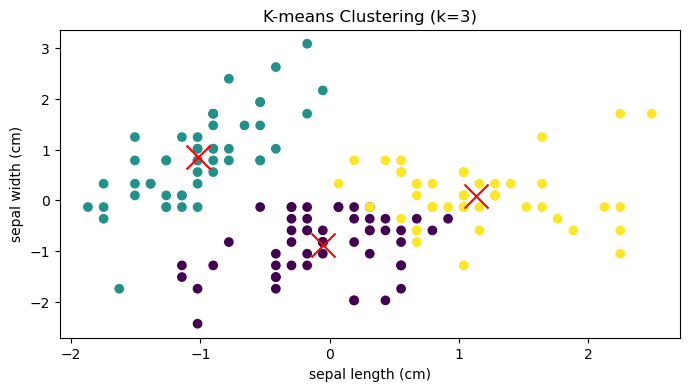

In [5]:
# Plot the clusters by looking to Sepal Length and Sepal Width
plt.figure(figsize=(8, 4))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap='viridis', marker='o')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='red', marker='x')
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title('K-means Clustering (k=3)')
plt.show()

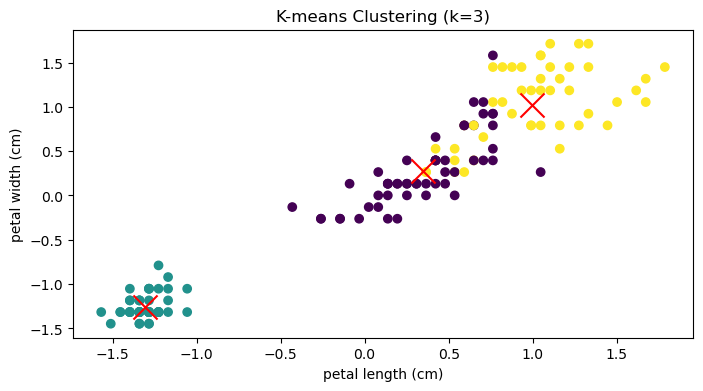

In [6]:
# Plot the clusters by looking to Petal Length and Petal Width
plt.figure(figsize=(8, 4))
plt.scatter(X_scaled[:, 2], X_scaled[:, 3], c=labels, cmap='viridis', marker='o')
plt.scatter(kmeans.cluster_centers_[:, 2], kmeans.cluster_centers_[:, 3], s=300, c='red', marker='x')
plt.xlabel(iris.feature_names[2])
plt.ylabel(iris.feature_names[3])
plt.title('K-means Clustering (k=3)')
plt.show()

### Evaluation of clusters' quality

Let's begining by checking clusters' cardinality

Cluster Cardinality:
{0: 53, 1: 50, 2: 47}


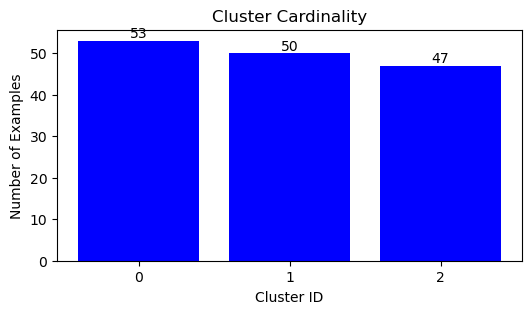

In [7]:
# Count the number of examples in each cluster
unique, counts = np.unique(labels, return_counts=True)
cluster_cardinality = dict(zip(unique, counts))

# Print the cluster cardinality
print("Cluster Cardinality:")
print(cluster_cardinality)

# Plot the cluster cardinality
plt.figure(figsize=(6, 3))
bars = plt.bar(cluster_cardinality.keys(), cluster_cardinality.values(), color='blue')
plt.xlabel('Cluster ID')
plt.ylabel('Number of Examples')
plt.title('Cluster Cardinality')
plt.xticks(list(cluster_cardinality.keys()))

# Annotate the bars with the number of examples
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval, int(yval), ha='center', va='bottom')

plt.show()

Let's verify clusters' magnitude

Cluster Magnitude:
[45.43744770865584, 40.68326094323137, 42.90734558589671]


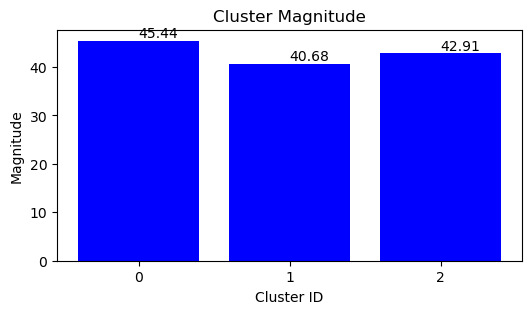

In [8]:
# Calculate the magnitude of each cluster
cluster_magnitude = []
for i in range(optimal_k):
    cluster_points = X_scaled[labels == i]
    centroid = kmeans.cluster_centers_[i]
    magnitude = np.sum(np.linalg.norm(cluster_points - centroid, axis=1))
    cluster_magnitude.append(magnitude)

# Print the cluster magnitude
print("Cluster Magnitude:")
print(cluster_magnitude)

# Plot the cluster magnitude with the values of each magnitude on top of the bars
plt.figure(figsize=(6, 3))
bars = plt.bar(range(optimal_k), cluster_magnitude, color='blue')
plt.xlabel('Cluster ID')
plt.ylabel('Magnitude')
plt.title('Cluster Magnitude')
plt.xticks(range(optimal_k))

# Add the magnitude values on top of the bars
for bar, magnitude in zip(bars, cluster_magnitude):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval, round(magnitude, 2), va='bottom') 

plt.show()

Since we know pretty well the iris data we can define the optimal number of clusters as being 3, but let's assume we do not know anything about this dataset ans let's check the elbow method to see what does it show to us

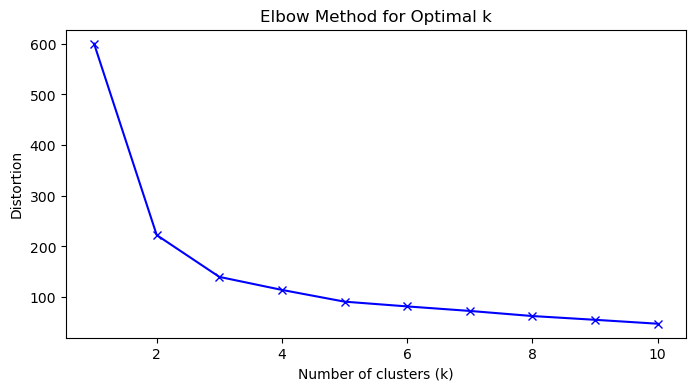

In [9]:
# Function to plot the elbow method
def plot_elbow_method(X, max_k=10):
    distortions = []
    K = range(1, max_k + 1)
    for k in K:
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(X)
        # inertia_ method returns Within-Cluster Sum of Square (wcss) for that model
        distortions.append(kmeans.inertia_)
    
    plt.figure(figsize=(8, 4))
    plt.plot(K, distortions, 'bx-')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Distortion')
    plt.title('Elbow Method for Optimal k')
    plt.show()

# Plot the elbow method to find the optimal number of clusters
plot_elbow_method(X_scaled)

Let's implement a different clustering that instead of using the distance of points to centroids such cluster will use a pairwise metric to define its clusters. 

First we need to install the following library:
* pip install scikit-learn-extra

For this example we will use KMedoids with the manhatthan pairwise distance.

$d(x,y) = \sum_{i=1}^n{|x_i - y_i|}$

Differently from KMeans which tries to minimize the sum of squares from all points to their centroids <b>(using the mean)</b> the KMedoids algorithm also tries to minimize the distance between the centroid and all the other points in the cluster but it will use the <b>median of such distances</b> to do so. The median value will make this algorithm more robust to outliers than the simple k-means.

In [12]:
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import pairwise_distances

# Compute the Manhattan distance matrix
manhattan_distances = pairwise_distances(X_scaled, metric='manhattan')

# Apply K-medoids clustering with Manhattan distance
kmedoids = KMedoids(n_clusters=optimal_k, metric='precomputed', random_state=42)
kmedoids.fit(manhattan_distances)
labels_manhattan = kmedoids.labels_

# Add cluster labels to the original dataset
iris_with_clusters_manhattan = np.column_stack((X, labels_manhattan))

# Print the cluster centers
print("Cluster Centers:")
print(X_scaled[kmedoids.medoid_indices_])

Cluster Centers:
[[-0.29484182 -0.82256978  0.25122143  0.13250973]
 [-1.02184904  0.78880759 -1.2833891  -1.3154443 ]
 [ 0.79566902 -0.13197948  0.99010798  0.79067065]]


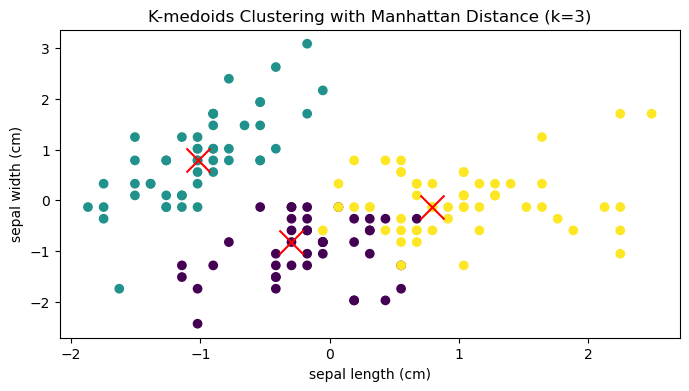

In [13]:
# Plot the clusters
plt.figure(figsize=(8, 4))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_manhattan, cmap='viridis', marker='o')
plt.scatter(X_scaled[kmedoids.medoid_indices_, 0], X_scaled[kmedoids.medoid_indices_, 1], s=300, c='red', marker='x')
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title('K-medoids Clustering with Manhattan Distance (k=3)')
plt.show()

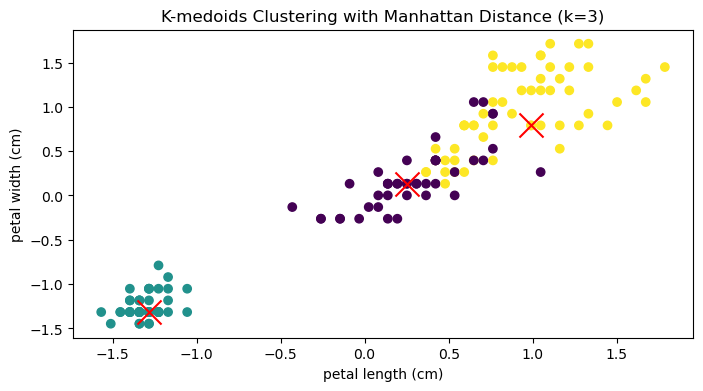

In [14]:
# Plot the clusters
plt.figure(figsize=(8, 4))
plt.scatter(X_scaled[:, 2], X_scaled[:, 3], c=labels_manhattan, cmap='viridis', marker='o')
plt.scatter(X_scaled[kmedoids.medoid_indices_, 2], X_scaled[kmedoids.medoid_indices_, 3], s=300, c='red', marker='x')
plt.xlabel(iris.feature_names[2])
plt.ylabel(iris.feature_names[3])
plt.title('K-medoids Clustering with Manhattan Distance (k=3)')
plt.show()